In [43]:
print("Hello Week 5, almost there")

Hello Week 5, almost there


## Task 1 - Dataset Understanding and Inspection

In [44]:
import pandas as pd
import numpy as np
 
df = pd.read_csv('/Users/siphomadlanga/Desktop/Week5_Morocco_Power/powerconsumption.csv')

print('rows, cols:', df.shape)
df.head()

rows, cols: (52416, 9)


,Datetime,Temperature,Humidity,WindSpeed,GeneralDiffuseFlows,DiffuseFlows,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
0,1/1/2017 0:00,6.559,73.8,0.083,0.051,0.119,34055.69620,16128.87538,20240.96386
1,1/1/2017 0:10,6.414,74.5,0.083,0.070,0.085,29814.68354,19375.07599,20131.08434
2,1/1/2017 0:20,6.313,74.5,0.080,0.062,0.100,29128.10127,19006.68693,19668.43373
3,1/1/2017 0:30,6.121,75.0,0.083,0.091,0.096,28228.86076,18361.09422,18899.27711
4,1/1/2017 0:40,5.921,75.7,0.081,0.048,0.085,27335.69620,17872.34043,18442.40964


In [45]:
print('Dimensions:', df.shape)
print('Columns:', df.columns.tolist())
print()
df.info()

Dimensions: (52416, 9)
Columns: ['Datetime', 'Temperature', 'Humidity', 'WindSpeed', 'GeneralDiffuseFlows', 'DiffuseFlows', 'PowerConsumption_Zone1', 'PowerConsumption_Zone2', 'PowerConsumption_Zone3']

<class 'pandas.DataFrame'>
RangeIndex: 52416 entries, 0 to 52415
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Datetime                52416 non-null  str    
 1   Temperature             52416 non-null  float64
 2   Humidity                52416 non-null  float64
 3   WindSpeed               52416 non-null  float64
 4   GeneralDiffuseFlows     52416 non-null  float64
 5   DiffuseFlows            52416 non-null  float64
 6   PowerConsumption_Zone1  52416 non-null  float64
 7   PowerConsumption_Zone2  52416 non-null  float64
 8   PowerConsumption_Zone3  52416 non-null  float64
dtypes: float64(8), str(1)
memory usage: 4.3 MB


**Note 1 - unit interpretation:** PowerConsumption_Zine1-3 are recorded in Kilowatt-Houra per 10-minute obsercation. Each reading is interpreted as the consumption level recorded at that observation, not automatically as total energy consumed during the interval. Pattern analysis therefore uses averages and comparisons; any summed totals are reported only with this interpretation stated explicitly. 

**Note 2 - diffuse flows:** The supplied descriptions state that GeneralDiffuseFlows and DiffuseFlows meaure emissions gases diffusing into the broader/local atmosphere, but the brief flags that their physical meaning is not sufficiently clear. Public sources on this dataset disagree on the meaning. Because of this ambiguity, these two columns are treated cautiosly and no conclusion rest on them alone.

In [46]:
print('Missing values per column:')
df.isna().sum()

Missing values per column:


Datetime                  0
Temperature               0
Humidity                  0
WindSpeed                 0
GeneralDiffuseFlows       0
DiffuseFlows              0
PowerConsumption_Zone1    0
PowerConsumption_Zone2    0
PowerConsumption_Zone3    0
dtype: int64

In [47]:
print('Full-row duplicates:', df.duplicated().sum())
print('Duplicate timestamps:', df['Datetime'].duplicated().sum())

Full-row duplicates: 0
Duplicate timestamps: 0


In [48]:
df['Datetime'] = pd.to_datetime(df['Datetime'])
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 52416 entries, 0 to 52415
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   Datetime                52416 non-null  datetime64[us]
 1   Temperature             52416 non-null  float64       
 2   Humidity                52416 non-null  float64       
 3   WindSpeed               52416 non-null  float64       
 4   GeneralDiffuseFlows     52416 non-null  float64       
 5   DiffuseFlows            52416 non-null  float64       
 6   PowerConsumption_Zone1  52416 non-null  float64       
 7   PowerConsumption_Zone2  52416 non-null  float64       
 8   PowerConsumption_Zone3  52416 non-null  float64       
dtypes: datetime64[us](1), float64(8)
memory usage: 3.6 MB


In [49]:
print('Earliest reading:', df['Datetime'].min())
print('Latest reading:  ', df['Datetime'].max())
print()
df.describe()

Earliest reading: 2017-01-01 00:00:00
Latest reading:   2017-12-30 23:50:00



,Datetime,Temperature,Humidity,WindSpeed,GeneralDiffuseFlows,DiffuseFlows,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
count,52416,52416.000000,52416.000000,52416.000000,52416.000000,52416.000000,52416.000000,52416.000000,52416.000000
mean,2017-07-01 23:55:00,18.810024,68.259518,1.959489,182.696614,75.028022,32344.970564,21042.509082,17835.406218
min,2017-01-01 00:00:00,3.247000,11.340000,0.050000,0.004000,0.011000,13895.696200,8560.081466,5935.174070
25%,2017-04-01 23:57:30,14.410000,58.310000,0.078000,0.062000,0.122000,26310.668692,16980.766032,13129.326630
50%,2017-07-01 23:55:00,18.780000,69.860000,0.086000,5.035500,4.456000,32265.920340,20823.168405,16415.117470
75%,2017-09-30 23:52:30,22.890000,81.400000,4.915000,319.600000,101.000000,37309.018185,24713.717520,21624.100420
max,2017-12-30 23:50:00,40.010000,94.800000,6.483000,1163.000000,936.000000,52204.395120,37408.860760,47598.326360
std,NaN,5.815476,15.551177,2.348862,264.400960,124.210949,7130.562564,5201.465892,6622.165099


In [50]:
df = df.sort_values('Datetime').reset_index(drop=True)

gaps = df['Datetime'].diff()
print(gaps.value_counts().head())
print('Readings NOT 10 minutes apart:', (gaps.dropna() != pd.Timedelta(minutes=10)).sum())

Datetime
0 days 00:10:00    52415
Name: count, dtype: int64
Readings NOT 10 minutes apart: 0


## Task 1 - Data Quality Summary
**Dataset:** powerconsumption.csv |**Size:** [52416 x 9] | **Period:** [2017-01-01 00:00:00 - 2017-12-30 23:50:00]

***Data dictionary reviewed.** Unit interpretation and diffuse-flows notes are above

**Missing values:**[0]
**Duplicates:** [full-row: 0] | [duplicates timestamps: 0]
**Extreme/unusual values:** ["non observed"]
**Interval consistency:** [0] readings not exactly 10 minutes apart; most common gap: [00:10:00]


In [51]:
zones = ['PowerConsumption_Zone1', 'PowerConsumption_Zone2', 'PowerConsumption_Zone3']
print('Helper ready:', zones)

Helper ready: ['PowerConsumption_Zone1', 'PowerConsumption_Zone2', 'PowerConsumption_Zone3']


In [52]:
print('Missing values per column:')
print(df.isna().sum())

Missing values per column:
Datetime                  0
Temperature               0
Humidity                  0
WindSpeed                 0
GeneralDiffuseFlows       0
DiffuseFlows              0
PowerConsumption_Zone1    0
PowerConsumption_Zone2    0
PowerConsumption_Zone3    0
dtype: int64


In [53]:
print('Duplicate timestamps before:', df['Datetime'].duplicated().sum())
df = df.drop_duplicates(subset='Datetime')
print('Duplicate timestamps after:', df['Datetime'].duplicated().sum())

Duplicate timestamps before: 0
Duplicate timestamps after: 0


In [54]:
df.describe().round(1)

,Datetime,Temperature,Humidity,WindSpeed,GeneralDiffuseFlows,DiffuseFlows,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
count,52416,52416.0,52416.0,52416.0,52416.0,52416.0,52416.0,52416.0,52416.0
mean,2017-07-01 23:55:00,18.8,68.3,2.0,182.7,75.0,32345.0,21042.5,17835.4
min,2017-01-01 00:00:00,3.2,11.3,0.0,0.0,0.0,13895.7,8560.1,5935.2
25%,2017-04-01 23:57:30,14.4,58.3,0.1,0.1,0.1,26310.7,16980.8,13129.3
50%,2017-07-01 23:55:00,18.8,69.9,0.1,5.0,4.5,32265.9,20823.2,16415.1
75%,2017-09-30 23:52:30,22.9,81.4,4.9,319.6,101.0,37309.0,24713.7,21624.1
max,2017-12-30 23:50:00,40.0,94.8,6.5,1163.0,936.0,52204.4,37408.9,47598.3
std,NaN,5.8,15.6,2.3,264.4,124.2,7130.6,5201.5,6622.2


In [55]:
df['Year'] = df['Datetime'].dt.year
df['Month'] = df['Datetime'].dt.month
df['Day'] = df['Datetime'].dt.day
df['Hour'] = df['Datetime'].dt.hour
df['DayOfWeek'] = df['Datetime'].dt.day_name()
df['Date'] = df['Datetime'].dt.date
 
df.head()

,Datetime,Temperature,Humidity,WindSpeed,GeneralDiffuseFlows,DiffuseFlows,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3,Year,Month,Day,Hour,DayOfWeek,Date
0,2017-01-01 00:00:00,6.559,73.8,0.083,0.051,0.119,34055.69620,16128.87538,20240.96386,2017,1,1,0,Sunday,2017-01-01
1,2017-01-01 00:10:00,6.414,74.5,0.083,0.070,0.085,29814.68354,19375.07599,20131.08434,2017,1,1,0,Sunday,2017-01-01
2,2017-01-01 00:20:00,6.313,74.5,0.080,0.062,0.100,29128.10127,19006.68693,19668.43373,2017,1,1,0,Sunday,2017-01-01
3,2017-01-01 00:30:00,6.121,75.0,0.083,0.091,0.096,28228.86076,18361.09422,18899.27711,2017,1,1,0,Sunday,2017-01-01
4,2017-01-01 00:40:00,5.921,75.7,0.081,0.048,0.085,27335.69620,17872.34043,18442.40964,2017,1,1,0,Sunday,2017-01-01


In [56]:
df.to_csv('powerconsumption_clean.csv', index=False)
print('Saved.')

Saved.


## Task 2 — Cleaning Summary
**Missing values:** [0]
**Duplicate timestamps:** [0;0]
**Extreme values:** [Temperature = 40]
**Time columns created:** Year, Month, Day, Hour, DayOfWeek, Date
**Cleaned dataset saved as:** powerconsumption_clean.csv

In [57]:
df[zones].mean().round(1)

PowerConsumption_Zone1    32345.0
PowerConsumption_Zone2    21042.5
PowerConsumption_Zone3    17835.4
dtype: float64

In [58]:
for z in zones:
    print(z)
    print('  highest reading at:', df.loc[df[z].idxmax(), 'Datetime'])
    print('  lowest reading at :', df.loc[df[z].idxmin(), 'Datetime'])

PowerConsumption_Zone1
  highest reading at: 2017-08-07 20:20:00
  lowest reading at : 2017-01-15 07:30:00
PowerConsumption_Zone2
  highest reading at: 2017-07-24 19:40:00
  lowest reading at : 2017-04-02 06:10:00
PowerConsumption_Zone3
  highest reading at: 2017-07-24 20:10:00
  lowest reading at : 2017-12-11 07:00:00


In [59]:
hourly = df.groupby('Hour')[zones].mean()
hourly.round(1)

,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
Hour,,,
0,30217.2,19692.1,18657.2
1,27565.5,17765.1,16970.8
2,26292.7,16730.2,15981.1
3,25338.1,16052.6,15238.6
4,24633.6,15624.1,14671.0
5,23437.6,14974.9,13226.4
6,23203.6,14934.7,12051.6
7,24038.4,15719.1,11667.9
8,26583.3,17529.7,12793.8


In [60]:
print('Zone 1 peak hour:', hourly['PowerConsumption_Zone1'].idxmax())
print('Zone 1 trough hour:', hourly['PowerConsumption_Zone1'].idxmin())

Zone 1 peak hour: 20
Zone 1 trough hour: 6


In [61]:
days = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
by_day = df.groupby('DayOfWeek')[zones].mean().loc[days]
by_day.round(1)

,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
DayOfWeek,,,
Monday,32615.4,21280.1,17809.1
Tuesday,32713.0,21518.6,17831.7
Wednesday,32871.8,21627.4,17851.4
Thursday,32842.5,21845.2,17843.7
Friday,32339.0,21461.0,17546.0
Saturday,32253.0,20586.0,18011.2
Sunday,30780.1,18979.4,17954.8


In [62]:
monthly = df.groupby('Month')[zones].mean()
monthly.round(1)
 
print('Zone 1 peak month:', monthly['PowerConsumption_Zone1'].idxmax())
print('Zone 1 trough month:', monthly['PowerConsumption_Zone1'].idxmin())

Zone 1 peak month: 8
Zone 1 trough month: 11


In [63]:
daily = df.groupby('Date')[zones].mean().reset_index()
daily

,Date,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
0,2017-01-01,28465.232067,17737.791287,17868.795181
1,2017-01-02,28869.493671,19557.725431,17820.763053
2,2017-01-03,30562.447257,20057.269504,17620.803213
3,2017-01-04,30689.831224,20102.077001,17673.694779
4,2017-01-05,30802.911393,20033.941237,17664.176707
...,...,...,...,...
359,2017-12-26,30013.476975,24757.006239,11395.678272
360,2017-12-27,29966.962399,25057.481845,11498.279312
361,2017-12-28,30267.004647,24585.251099,11167.026811
362,2017-12-29,29209.632446,24610.821315,11171.268507


## Task 3 - Consumption Patters
**Zone ranking (average kWh):** [Zone1: x | Zone2: y | Zone3: z]
**Peak hour:** [20]:00 | **Trough hour:** [6]:00
**Weekday vs weekend:** Consumption increases on weekends in Zone 3, but in zone 1 and 2 Sunday being the lowest. 
**Peak month:** [8] | **Trough month:** [11]
**Highest single moments:** [1, 20:20:00], [2, 19:40:00],[3, 20:10:00] | **Lowest:** [1, 07:30:00], [2, 06:10:00], [3, 07:00:00]

In [64]:
corr = df[['Temperature', 'Humidity', 'WindSpeed'] + zones].corr()
corr.loc[['Temperature', 'Humidity', 'WindSpeed'], zones].round(2)

,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
Temperature,0.44,0.38,0.49
Humidity,-0.29,-0.29,-0.23
WindSpeed,0.17,0.15,0.28


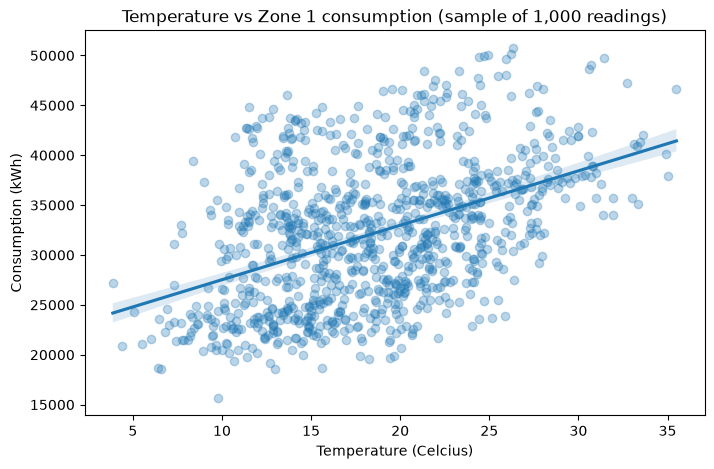

In [65]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
sns.regplot(data=df.sample(1000), x='Temperature', y='PowerConsumption_Zone1', scatter_kws={'alpha': 0.3})
plt.title('Temperature vs Zone 1 consumption (sample of 1,000 readings)')
plt.xlabel('Temperature (Celcius)')
plt.ylabel('Consumption (kWh)')
plt.show()

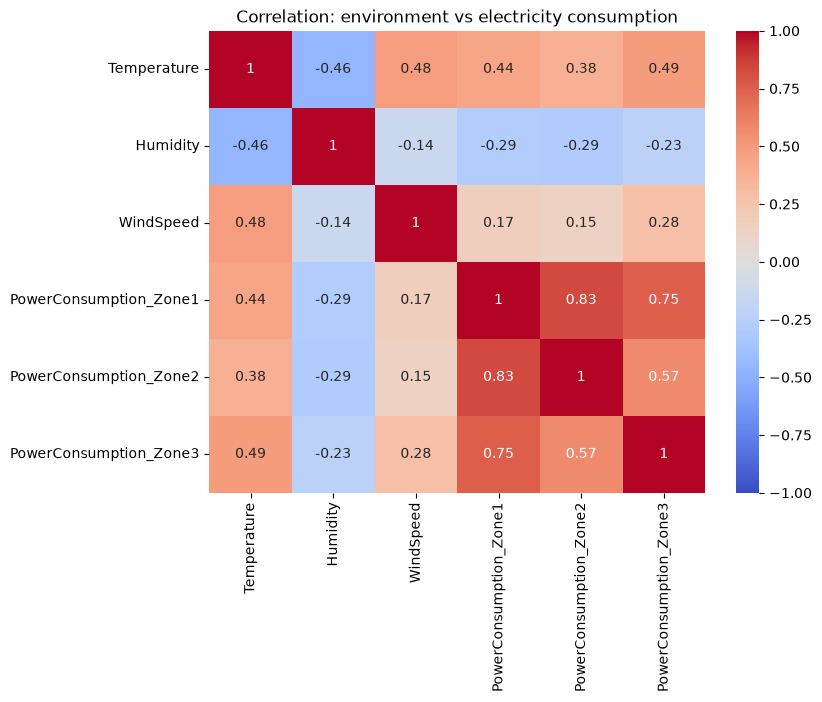

In [66]:
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation: environment vs electricity consumption')
plt.show()

## Task 4 - Environmental Relationships
**Strongest environmental link:** Temperature vs Zone [3] at [0.49] - hotter periods coincide with higher consumption (associarion, not causarion, per the brief.)

**Humidity:** [-0.23] **Wind speed:** [0.28] - weaker than temperature

**Reading:** temperature is the environmental variable worth watching for demand planning; humidity and wind add little.

In [67]:
short = {'PowerConsumption_Zone1': 'Zone 1',
         'PowerConsumption_Zone2': 'Zone 2',
         'PowerConsumption_Zone3': 'Zone 3'}

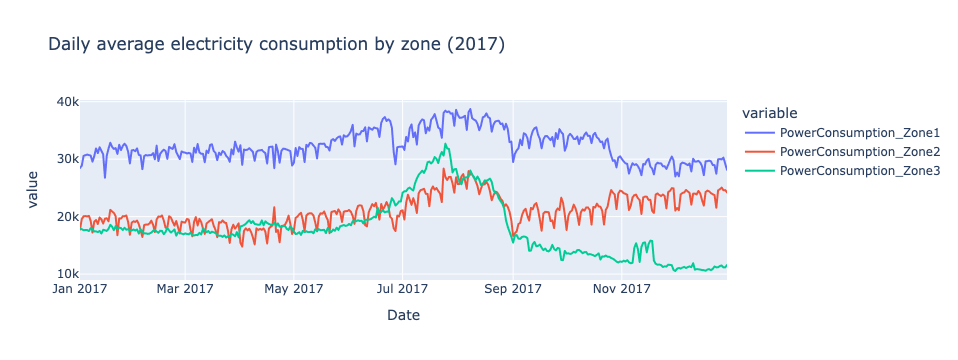

In [68]:
import plotly.express as px
 
fig = px.line(daily, x='Date', y=zones,
              title='Daily average electricity consumption by zone (2017)')
fig.show()

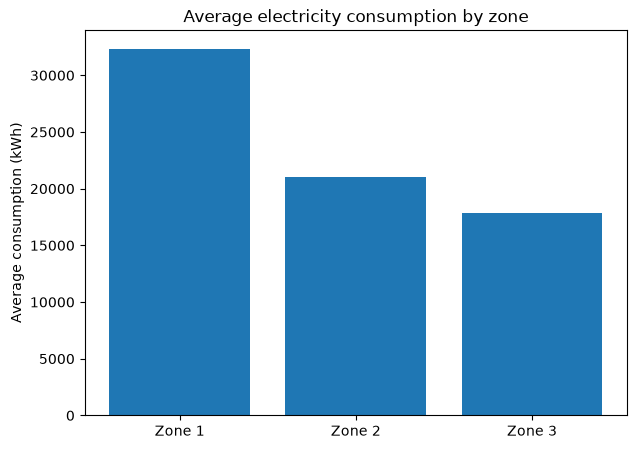

In [69]:
plt.figure(figsize=(7, 5))
plt.bar(['Zone 1', 'Zone 2', 'Zone 3'], df[zones].mean())
plt.title('Average electricity consumption by zone')
plt.ylabel('Average consumption (kWh)')
plt.show()

Text(0.5, 0, 'Hour of day (0-23)')

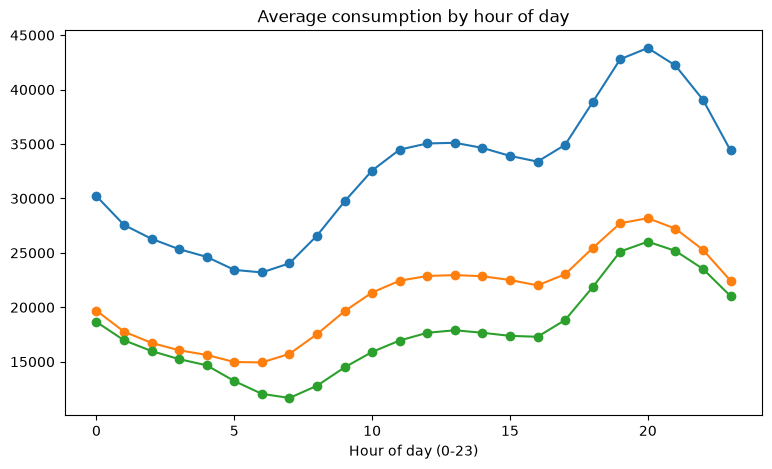

In [70]:
plt.figure(figsize=(9, 5))
for z in zones:
    plt.plot(hourly.index, hourly[z], marker='o', label=short[z])
plt.title('Average consumption by hour of day')
plt.xlabel('Hour of day (0-23)')

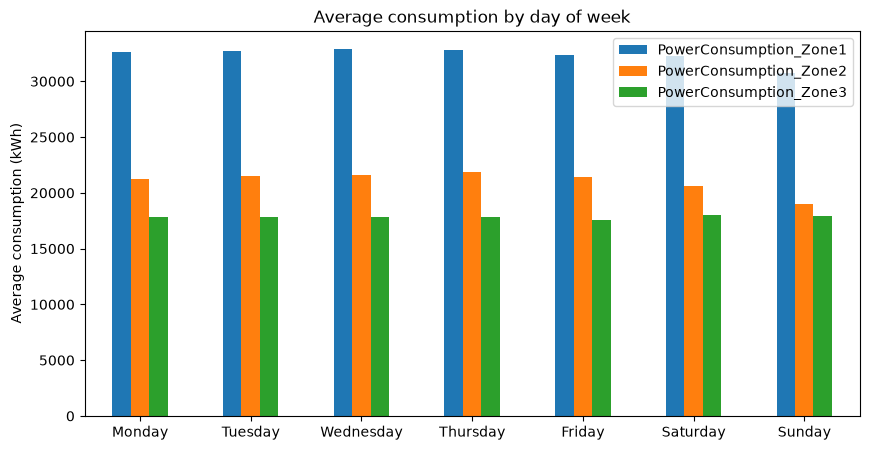

In [71]:
by_day.plot(kind='bar', figsize=(10, 5))
plt.title('Average consumption by day of week')
plt.xlabel('')
plt.ylabel('Average consumption (kWh)')
plt.xticks(rotation=0)
plt.show()

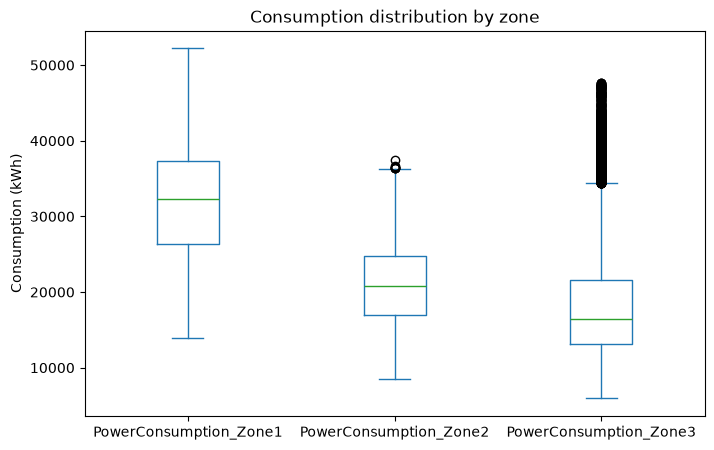

In [72]:
df[zones].plot(kind='box', figsize=(8, 5))
plt.title('Consumption distribution by zone')
plt.ylabel('Consumption (kWh)')
plt.show()

In [73]:
plt.savefig('chart_name.png', dpi=150, bbox_inches='tight')

<Figure size 640x480 with 0 Axes>